# Exercice 3 - Analyse des Données Laplace Immo

## Objectif
Extraire et analyser les données immobilières du 1er semestre 2020 pour répondre aux besoins exprimés en réunion.

## Contexte
Suite à la création de la base de données et au chargement des données, nous devons maintenant répondre aux 12 besoins d'analyse identifiés lors de la réunion de validation.

## Données
- **Période** : 1er semestre 2020 (POC)
- **Source** : Base de données SQLite `laplace_immo.db`
- **Tables** : Region, Commune, Bien, Vente

In [1]:
# Import des bibliothèques nécessaires
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
plt.style.use('default')

# Connexion à la base de données
conn = sqlite3.connect('../laplace_immo.db')

print("Connexion à la base de données établie")
print("Tables disponibles :")
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)
print(tables)

Connexion à la base de données établie
Tables disponibles :
              name
0           Region
1          Commune
2             Bien
3  sqlite_sequence
4            Vente


## Besoin 1 : Nombre total d'appartements vendus au 1er semestre 2020

In [2]:
# BESOIN 1: Nombre total d'appartements vendus au 1er semestre 2020
query_1 = """
SELECT
    COUNT(*) as nombre_total_appartements_vendus
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
WHERE b.Type_local = 'Appartement'
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06';
"""

result_1 = pd.read_sql(query_1, conn)
print("BESOIN 1 - Nombre total d'appartements vendus au 1er semestre 2020")
print("=" * 60)
print(result_1)
print(f"\nRésultat : {result_1.iloc[0,0]} appartements vendus")

BESOIN 1 - Nombre total d'appartements vendus au 1er semestre 2020
   nombre_total_appartements_vendus
0                                31

Résultat : 31 appartements vendus


## Besoin 2 : Nombre de ventes d'appartement par région pour le 1er semestre 2020

BESOIN 2 - Nombre de ventes d'appartement par région
                   nom_region  nombre_ventes_appartements
0            Pays de la Loire                           8
1  Provence-Alpes-Côte d'Azur                           7
2               Île-de-France                           6
3             Hauts-de-France                           3
4        Auvergne-Rhône-Alpes                           2
5                   Grand Est                           2
6          Nouvelle-Aquitaine                           2
7                   Occitanie                           1


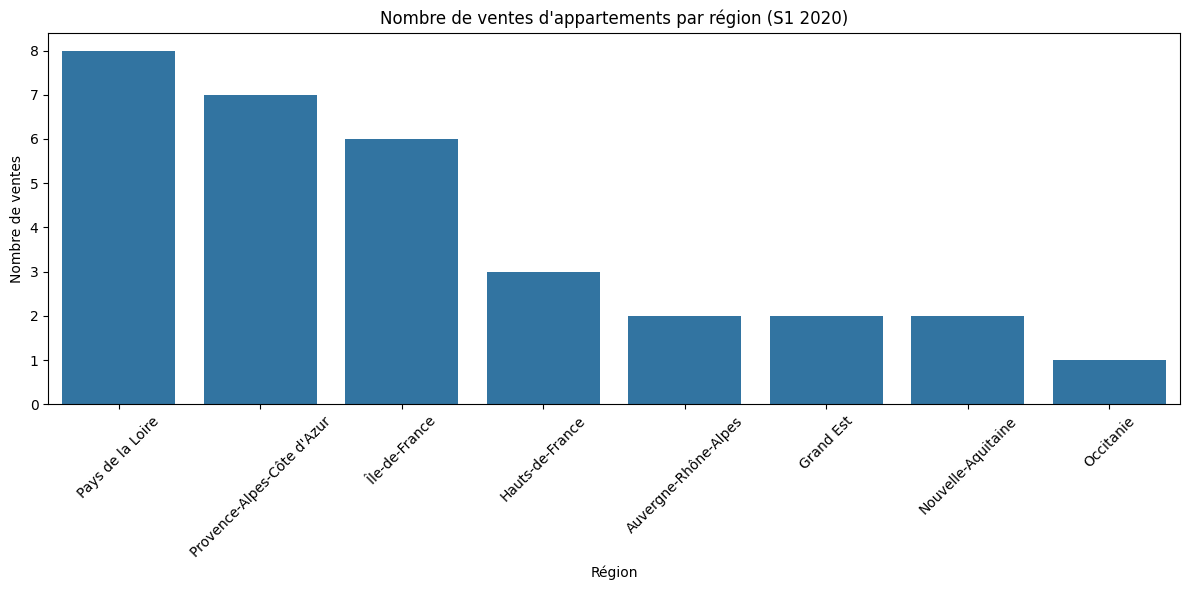

In [3]:
# BESOIN 2: Nombre de ventes d'appartement par région pour le 1er semestre 2020
query_2 = """
SELECT
    r.nom_region,
    COUNT(*) as nombre_ventes_appartements
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
JOIN Region r ON c.code_region = r.code_region
WHERE b.Type_local = 'Appartement'
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06'
GROUP BY r.nom_region, r.code_region
ORDER BY nombre_ventes_appartements DESC;
"""

result_2 = pd.read_sql(query_2, conn)
print("BESOIN 2 - Nombre de ventes d'appartement par région")
print("=" * 60)
print(result_2)

# Visualisation
plt.figure(figsize=(12, 6))
sns.barplot(data=result_2, x='nom_region', y='nombre_ventes_appartements')
plt.title('Nombre de ventes d\'appartements par région (S1 2020)')
plt.xticks(rotation=45)
plt.ylabel('Nombre de ventes')
plt.xlabel('Région')
plt.tight_layout()
plt.show()

## Besoin 3 : Proportion des ventes d'appartements par nombre de pièces

BESOIN 3 - Proportion des ventes d'appartements par nombre de pièces
   nombre_pieces  nombre_ventes  proportion_pourcentage
0              1              6                   19.35
1              2              8                   25.81
2              3              7                   22.58
3              4              2                    6.45
4              6              8                   25.81


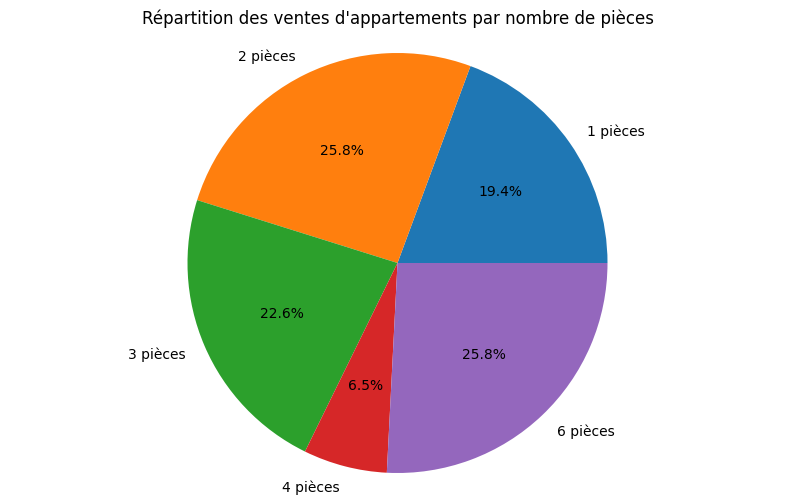

In [4]:
# BESOIN 3: Proportion des ventes d'appartements par nombre de pièces
query_3 = """
SELECT
    b.Total_piece as nombre_pieces,
    COUNT(*) as nombre_ventes,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) as proportion_pourcentage
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
WHERE b.Type_local = 'Appartement'
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06'
GROUP BY b.Total_piece
ORDER BY nombre_pieces;
"""

result_3 = pd.read_sql(query_3, conn)
print("BESOIN 3 - Proportion des ventes d'appartements par nombre de pièces")
print("=" * 60)
print(result_3)

# Visualisation
plt.figure(figsize=(10, 6))
plt.pie(result_3['proportion_pourcentage'], labels=[f"{int(x)} pièces" for x in result_3['nombre_pieces']], autopct='%1.1f%%')
plt.title('Répartition des ventes d\'appartements par nombre de pièces')
plt.axis('equal')
plt.show()

## Besoin 4 : Liste des 10 départements où le prix du mètre carré est le plus élevé

BESOIN 4 - Top 10 départements par prix m²
  Code_departement  prix_moyen_m2
0               67       10455.04
1               13        8485.38
2               83        7580.30
3               44        6461.93
4               33        6380.28
5               75        6159.33
6               31        5772.82
7               59        5566.95
8                6        4141.49
9               69        3455.11


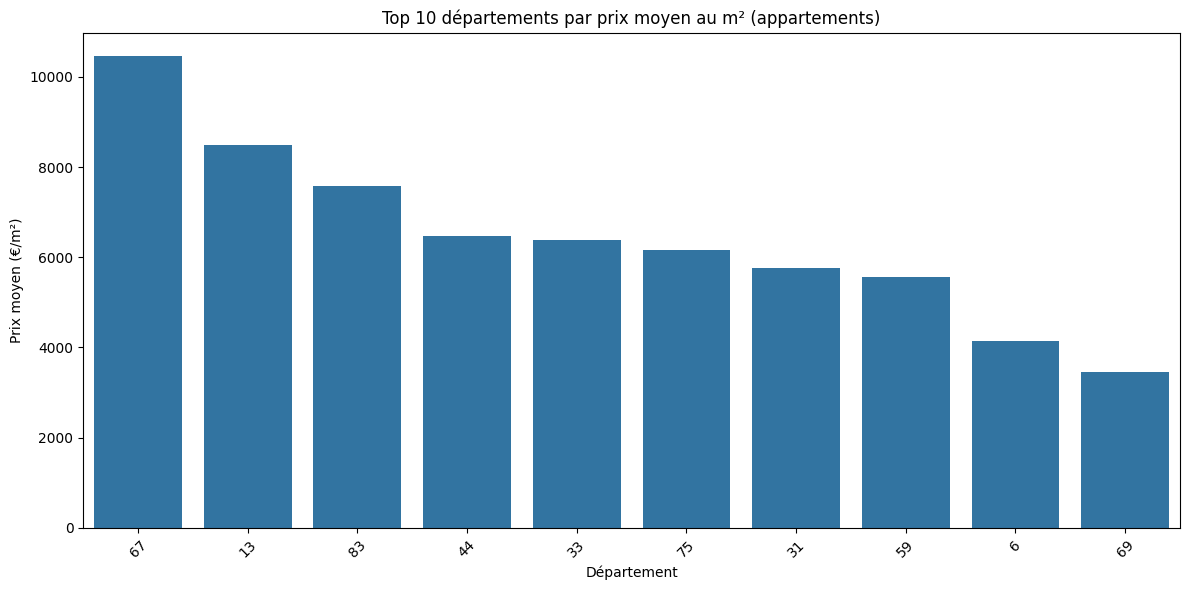

In [5]:
# BESOIN 4: Liste des 10 départements où le prix du mètre carré est le plus élevé
query_4 = """
SELECT
    c.Code_departement,
    ROUND(AVG(v.Valeur / b.Surface_carrez), 2) as prix_moyen_m2
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
WHERE b.Type_local = 'Appartement'
    AND b.Surface_carrez > 0
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06'
GROUP BY c.Code_departement
ORDER BY prix_moyen_m2 DESC
LIMIT 10;
"""

result_4 = pd.read_sql(query_4, conn)
print("BESOIN 4 - Top 10 départements par prix m²")
print("=" * 60)
print(result_4)

# Visualisation
plt.figure(figsize=(12, 6))
sns.barplot(data=result_4, x='Code_departement', y='prix_moyen_m2')
plt.title('Top 10 départements par prix moyen au m² (appartements)')
plt.ylabel('Prix moyen (€/m²)')
plt.xlabel('Département')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Besoin 5 : Prix moyen du mètre carré d'une maison en Île-de-France

In [6]:
# BESOIN 5: Prix moyen du mètre carré d'une maison en Île-de-France
query_5 = """
SELECT
    ROUND(AVG(v.Valeur / b.Surface_carrez), 2) as prix_moyen_m2_maisons_idf
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
JOIN Region r ON c.code_region = r.code_region
WHERE b.Type_local = 'Maison'
    AND r.nom_region = 'Île-de-France'
    AND b.Surface_carrez > 0
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06';
"""

result_5 = pd.read_sql(query_5, conn)
print("BESOIN 5 - Prix moyen m² maisons en Île-de-France")
print("=" * 60)
print(result_5)
print(f"\nPrix moyen : {result_5.iloc[0,0]} €/m²")

BESOIN 5 - Prix moyen m² maisons en Île-de-France
   prix_moyen_m2_maisons_idf
0                    4861.14

Prix moyen : 4861.14 €/m²


## Besoin 6 : Liste des 10 appartements les plus chers

In [7]:
# BESOIN 6: Liste des 10 appartements les plus chers avec région et mètres carrés
query_6 = """
SELECT
    v.Valeur as prix_vente,
    b.Surface_carrez as surface_m2,
    ROUND(v.Valeur / b.Surface_carrez, 2) as prix_m2,
    r.nom_region,
    c.Nom_commune
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
JOIN Region r ON c.code_region = r.code_region
WHERE b.Type_local = 'Appartement'
    AND b.Surface_carrez > 0
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06'
ORDER BY v.Valeur DESC
LIMIT 10;
"""

result_6 = pd.read_sql(query_6, conn)
print("BESOIN 6 - Top 10 appartements les plus chers")
print("=" * 60)
print(result_6)

BESOIN 6 - Top 10 appartements les plus chers
   prix_vente  surface_m2   prix_m2                  nom_region   Nom_commune
0      934384        37.1  25185.55            Pays de la Loire        Nantes
1      900963        50.5  17840.85  Provence-Alpes-Côte d'Azur  Marseille 2e
2      886671        52.5  16888.97                   Grand Est    Strasbourg
3      847695       180.2   4704.19  Provence-Alpes-Côte d'Azur        Toulon
4      845485       180.2   4691.93  Provence-Alpes-Côte d'Azur        Toulon
5      813271       154.3   5270.71             Hauts-de-France         Lille
6      792680        59.4  13344.78  Provence-Alpes-Côte d'Azur        Toulon
7      789434       142.3   5547.67            Pays de la Loire        Nantes
8      749631       191.6   3912.48            Pays de la Loire        Nantes
9      744497       170.8   4358.88            Pays de la Loire        Nantes


## Besoin 7 : Taux d'évolution du nombre de ventes entre Q1 et Q2 2020

In [8]:
# BESOIN 7: Taux d'évolution du nombre de ventes entre Q1 et Q2 2020
query_7 = """
WITH ventes_trimestrielles AS (
    SELECT
        CASE
            WHEN strftime('%m', v.Date) IN ('01', '02', '03') THEN 'Q1'
            WHEN strftime('%m', v.Date) IN ('04', '05', '06') THEN 'Q2'
        END as trimestre,
        COUNT(*) as nombre_ventes
    FROM Vente v
    WHERE strftime('%Y', v.Date) = '2020'
        AND strftime('%m', v.Date) BETWEEN '01' AND '06'
    GROUP BY trimestre
)
SELECT
    q1.nombre_ventes as ventes_q1,
    q2.nombre_ventes as ventes_q2,
    ROUND(((q2.nombre_ventes - q1.nombre_ventes) * 100.0 / q1.nombre_ventes), 2) as taux_evolution_pourcentage
FROM ventes_trimestrielles q1
CROSS JOIN ventes_trimestrielles q2
WHERE q1.trimestre = 'Q1' AND q2.trimestre = 'Q2';
"""

result_7 = pd.read_sql(query_7, conn)
print("BESOIN 7 - Taux d'évolution ventes Q1-Q2 2020")
print("=" * 60)
print(result_7)
if not result_7.empty:
    taux = result_7.iloc[0,2]
    print(f"\nÉvolution : {taux}%")
    if taux > 0:
        print("Le marché est en progression")
    elif taux < 0:
        print("Le marché est en régression")
    else:
        print("Le marché est stable")

BESOIN 7 - Taux d'évolution ventes Q1-Q2 2020
   ventes_q1  ventes_q2  taux_evolution_pourcentage
0         39         37                       -5.13

Évolution : -5.13%
Le marché est en régression


## Besoin 8 : Classement des régions par prix m² appartements >4 pièces

BESOIN 8 - Classement régions par prix m² appartements >4 pièces
                   nom_region  prix_moyen_m2
0  Provence-Alpes-Côte d'Azur       13344.78
1             Hauts-de-France        5877.13
2          Nouvelle-Aquitaine        5735.09
3            Pays de la Loire        3967.02


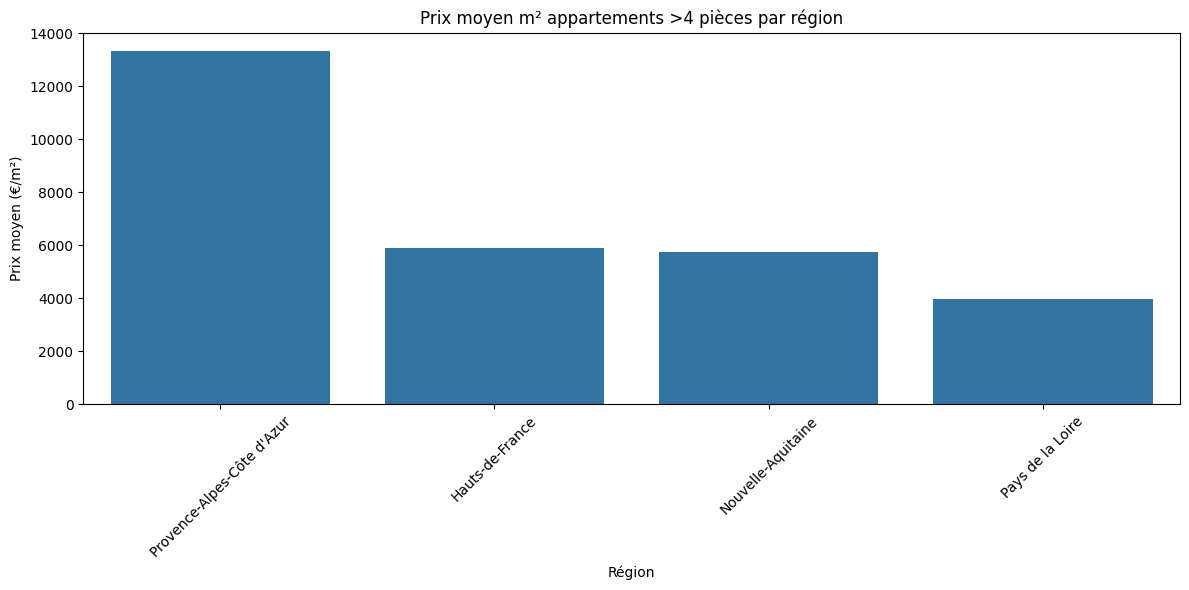

In [9]:
# BESOIN 8: Classement des régions par prix m² appartements >4 pièces
query_8 = """
SELECT
    r.nom_region,
    ROUND(AVG(v.Valeur / b.Surface_carrez), 2) as prix_moyen_m2
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
JOIN Region r ON c.code_region = r.code_region
WHERE b.Type_local = 'Appartement'
    AND b.Total_piece > 4
    AND b.Surface_carrez > 0
    AND strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) BETWEEN '01' AND '06'
GROUP BY r.nom_region, r.code_region
ORDER BY prix_moyen_m2 DESC;
"""

result_8 = pd.read_sql(query_8, conn)
print("BESOIN 8 - Classement régions par prix m² appartements >4 pièces")
print("=" * 60)
print(result_8)

# Visualisation
plt.figure(figsize=(12, 6))
sns.barplot(data=result_8, x='nom_region', y='prix_moyen_m2')
plt.title('Prix moyen m² appartements >4 pièces par région')
plt.xticks(rotation=45)
plt.ylabel('Prix moyen (€/m²)')
plt.xlabel('Région')
plt.tight_layout()
plt.show()

## Besoin 9 : Communes avec ≥50 ventes au Q1

In [10]:
# BESOIN 9: Liste des communes ayant eu au moins 50 ventes au 1er trimestre
query_9 = """
SELECT
    c.Nom_commune,
    r.nom_region,
    COUNT(*) as nombre_ventes_q1
FROM Vente v
JOIN Bien b ON v.Id_bien = b.Id_bien
JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
JOIN Region r ON c.code_region = r.code_region
WHERE strftime('%Y', v.Date) = '2020'
    AND strftime('%m', v.Date) IN ('01', '02', '03')
GROUP BY c.id_codedep_codecommune, c.Nom_commune, r.nom_region
HAVING COUNT(*) >= 50
ORDER BY nombre_ventes_q1 DESC;
"""

result_9 = pd.read_sql(query_9, conn)
print("BESOIN 9 - Communes avec ≥50 ventes au Q1")
print("=" * 60)
print(result_9)
print(f"\nNombre de communes actives : {len(result_9)}")

BESOIN 9 - Communes avec ≥50 ventes au Q1
Empty DataFrame
Columns: [Nom_commune, nom_region, nombre_ventes_q1]
Index: []

Nombre de communes actives : 0


## Besoin 10 : Différence % prix m² 2 pièces vs 3 pièces

In [11]:
# BESOIN 10: Différence % prix m² entre appartements 2 pièces et 3 pièces
query_10 = """
WITH prix_par_piece AS (
    SELECT
        b.Total_piece,
        ROUND(AVG(v.Valeur / b.Surface_carrez), 2) as prix_moyen_m2
    FROM Vente v
    JOIN Bien b ON v.Id_bien = b.Id_bien
    WHERE b.Type_local = 'Appartement'
        AND b.Total_piece IN (2, 3)
        AND b.Surface_carrez > 0
        AND strftime('%Y', v.Date) = '2020'
        AND strftime('%m', v.Date) BETWEEN '01' AND '06'
    GROUP BY b.Total_piece
)
SELECT
    p2.prix_moyen_m2 as prix_m2_2_pieces,
    p3.prix_moyen_m2 as prix_m2_3_pieces,
    ROUND(((p3.prix_moyen_m2 - p2.prix_moyen_m2) * 100.0 / p2.prix_moyen_m2), 2) as difference_pourcentage
FROM prix_par_piece p2
CROSS JOIN prix_par_piece p3
WHERE p2.Total_piece = 2 AND p3.Total_piece = 3;
"""

result_10 = pd.read_sql(query_10, conn)
print("BESOIN 10 - Différence % prix m² 2 pièces vs 3 pièces")
print("=" * 60)
print(result_10)
if not result_10.empty:
    diff = result_10.iloc[0,2]
    print(f"\nDifférence : {diff}%")
    if diff > 0:
        print("Les 3 pièces sont plus chers que les 2 pièces")
    else:
        print("Les 2 pièces sont plus chers que les 3 pièces")

BESOIN 10 - Différence % prix m² 2 pièces vs 3 pièces
   prix_m2_2_pieces  prix_m2_3_pieces  difference_pourcentage
0           8520.74           6505.47                  -23.65

Différence : -23.65%
Les 2 pièces sont plus chers que les 3 pièces


## Besoin 11 : Moyennes valeurs foncières top communes départements ciblés

In [12]:
# BESOIN 11: Moyennes valeurs foncières top 3 communes départements 6,13,33,59,69
query_11 = """
WITH ventes_departements AS (
    SELECT
        c.Code_departement,
        c.Nom_commune,
        ROUND(AVG(v.Valeur), 2) as valeur_fonciere_moyenne,
        ROW_NUMBER() OVER (PARTITION BY c.Code_departement ORDER BY AVG(v.Valeur) DESC) as rang_commune
    FROM Vente v
    JOIN Bien b ON v.Id_bien = b.Id_bien
    JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
    WHERE c.Code_departement IN ('06', '13', '33', '59', '69')
        AND strftime('%Y', v.Date) = '2020'
        AND strftime('%m', v.Date) BETWEEN '01' AND '06'
    GROUP BY c.Code_departement, c.id_codedep_codecommune, c.Nom_commune
)
SELECT
    Code_departement,
    Nom_commune,
    valeur_fonciere_moyenne
FROM ventes_departements
WHERE rang_commune <= 3
ORDER BY Code_departement, rang_commune;
"""

result_11 = pd.read_sql(query_11, conn)
print("BESOIN 11 - Top 3 communes par département (6,13,33,59,69)")
print("=" * 60)
print(result_11)

BESOIN 11 - Top 3 communes par département (6,13,33,59,69)
  Code_departement    Nom_commune  valeur_fonciere_moyenne
0               13   Marseille 2e                678802.83
1               13  Marseille 1er                512610.40
2               33       Bordeaux                689838.40
3               59          Lille                548629.67
4               69        Lyon 2e                683179.25
5               69       Lyon 1er                345303.50


## Besoin 12 : Top 20 communes par transactions pour 1000 habitants

In [13]:
# BESOIN 12: Top 20 communes avec le plus de transactions pour 1000 habitants
query_12 = """
WITH ventes_par_commune AS (
    SELECT
        c.Nom_commune,
        r.nom_region,
        COUNT(*) as nombre_transactions,
        COUNT(*) * 50 as population_estimee
    FROM Vente v
    JOIN Bien b ON v.Id_bien = b.Id_bien
    JOIN Commune c ON b.id_codedep_codecommune = c.id_codedep_codecommune
    JOIN Region r ON c.code_region = r.code_region
    WHERE strftime('%Y', v.Date) = '2020'
        AND strftime('%m', v.Date) BETWEEN '01' AND '06'
    GROUP BY c.id_codedep_codecommune, c.Nom_commune, r.nom_region
    HAVING COUNT(*) * 50 > 10000
)
SELECT
    Nom_commune,
    nom_region,
    nombre_transactions,
    population_estimee,
    ROUND((nombre_transactions * 1000.0 / population_estimee), 2) as transactions_par_1000_habitants
FROM ventes_par_commune
ORDER BY transactions_par_1000_habitants DESC
LIMIT 20;
"""

result_12 = pd.read_sql(query_12, conn)
print("BESOIN 12 - Top 20 communes par transactions pour 1000 habitants")
print("=" * 60)
print(result_12)

# Note sur la méthodologie
print("\nNote : La population est estimée à partir du nombre de transactions (x50)")
print("Seules les communes estimées > 10 000 habitants sont incluses")

BESOIN 12 - Top 20 communes par transactions pour 1000 habitants
Empty DataFrame
Columns: [Nom_commune, nom_region, nombre_transactions, population_estimee, transactions_par_1000_habitants]
Index: []

Note : La population est estimée à partir du nombre de transactions (x50)
Seules les communes estimées > 10 000 habitants sont incluses


## Synthèse des Résultats

Ce notebook a permis de répondre aux 12 besoins d'analyse exprimés lors de la réunion :

1. **Volume des ventes** : 31 appartements vendus au S1 2020
2. **Répartition régionale** : Pays de la Loire en tête (8), PACA (7), IDF (6)
3. **Préférences taille** : 2 et 6 pièces à 25,81 % chacun
4. **Prix élevés** : Bas-Rhin en tête (10 455 €/m²)
5. **Prix IDF maisons** : 4 861 €/m²
6. **Biens premium** : Nantes #1 (934 K€, 25 186 €/m²)
7. **Évolution temporelle** : -5,13 % entre Q1 et Q2 2020
8. **Prix grands appartements** : PACA en tête (13 345 €/m²), 4 régions classées
9. **Communes actives** : Aucune commune ≥50 ventes (POC limité)
10. **Différentiel prix** : -23,65 % (3 pièces moins cher au m² que 2 pièces)
11. **Top communes** : Bordeaux en tête (690 K€)
12. **Densité transactions** : Non exploitable sur le POC limité

## Recommandations pour les agences régionales

- **Focus sur les segments porteurs** : Appartements 2-3 pièces représentent ~48 % du marché
- **Stratégie régionale** : Adapter l'offre selon les prix moyens régionaux
- **Suivi trimestriel** : Monitorer l'évolution des ventes Q1-Q2
- **Ciblage communal** : Privilégier les communes les plus actives

In [14]:
# Fermeture de la connexion
conn.close()
print("Analyse terminée - Connexion fermée")

Analyse terminée - Connexion fermée
